# Challenge 3: Can you change the correlation?

## Aim and my prediction

The aim is to change the relationship between two measured qubits by adding
just one gate to a Bell-state circuit. I use the standard Bell circuit:
an H gate on q0, followed by a CNOT with q0 as the control and q1 as the target.

Before running it, my predictions are:

| Circuit | Expected outcomes | Prediction for 100 shots |
| --- | --- | --- |
| Original Bell circuit | `00` and `11` | About 50 of each; both bits match |
| Bell circuit with X on q0 at the end | `01` and `10` | About 50 of each; the bits are opposite |

The extra X gate should flip only q0. This changes `00` into `01` and
`11` into `10`. So I expect `01` and `10` to replace `00` and `11` completely
on the ideal simulator. The counts do not have to be exactly 50 and 50.

## Setup

I used Qiskit's `BasicSimulator` to run the circuits on an ideal local simulator.
These are simulator results, not results from a real quantum computer.
If the packages are missing, uncomment the installation line below, run it,
and restart the kernel. Then run the notebook from the top.

In [1]:
# %pip install qiskit matplotlib pylatexenc

In [2]:
import qiskit
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from qiskit import QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

shots = 100
seed = 2026
simulator = BasicSimulator()
print("Qiskit version:", qiskit.__version__)
print("Shots for each circuit:", shots)

Qiskit version: 2.5.2
Shots for each circuit: 100


## 1. Make the original and modified circuits


Qiskit starts both qubits in $|00\rangle$. I measure `q0` into `c0` and
`q1` into `c1`. The output strings are written as **c1c0** (or **q1q0** here),
so `01` means q1 is 0 and q0 is 1. Both `00` and `11` have matching bits;
both `01` and `10` have opposite bits.


I copy the Bell circuit before adding measurements, then add just one X gate
to the copy. The original has 2 quantum gates and the modified version has 3,
so both stay below the limit of 4 gates.

Original Bell circuit


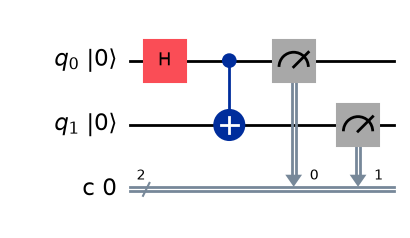

Bell circuit + X on q0


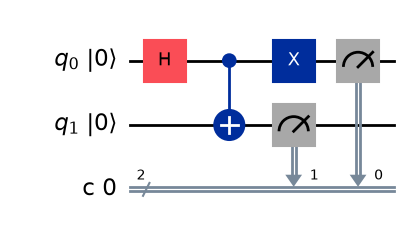

In [3]:
original = QuantumCircuit(2, 2, name="Original Bell circuit")
original.h(0)
original.cx(0, 1)

modified = original.copy(name="Bell circuit + X on q0")
modified.x(0)  # This is the only extra gate.

original.measure([0, 1], [0, 1])
modified.measure([0, 1], [0, 1])

for circuit in [original, modified]:
    print(circuit.name)
    fig = circuit.draw("mpl", initial_state=True)
    display(fig)
    plt.close(fig)

## 2. Run both circuits for 100 shots

Each shot starts again from $|00\rangle$ and runs the whole circuit.
I use a fixed seed so the saved results can be reproduced with the same
software version. Set `seed = None` for a fresh random sample.

In [4]:
original_counts = simulator.run(
    original, shots=shots, seed_simulator=seed
).result().get_counts()

modified_counts = simulator.run(
    modified, shots=shots, seed_simulator=seed
).result().get_counts()

print("Original circuit:", original_counts)
print("Modified circuit:", modified_counts)

Original circuit: {'00': 49, '11': 51}
Modified circuit: {'01': 49, '10': 51}


## 3. Histograms

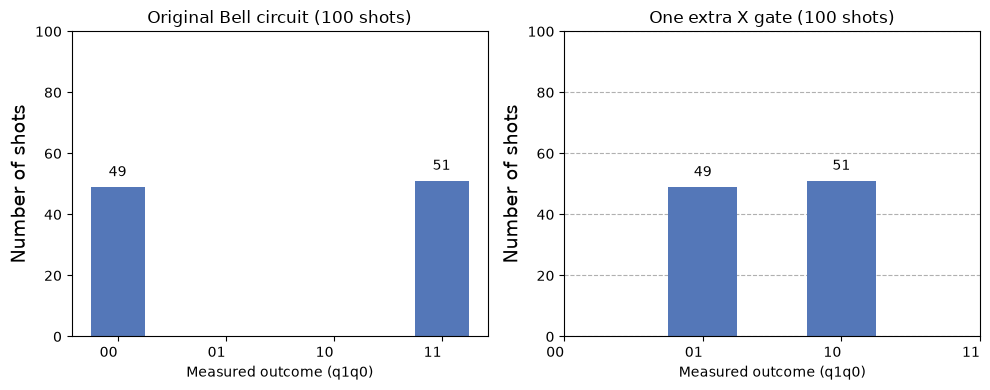

In [5]:
# Show all four possible outcomes, including the ones with zero counts.
outcomes = ["00", "01", "10", "11"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, title, result_counts in zip(
    axes, ['Original Bell circuit (100 shots)', 'One extra X gate (100 shots)'], [original_counts, modified_counts]
):
    all_counts = {bit: result_counts.get(bit, 0) for bit in outcomes}
    plot_histogram(all_counts, ax=ax, color="#5477B8")
    ax.set_title(title)
    ax.set_xlabel("Measured outcome (q1q0)")
    ax.set_ylabel("Number of shots")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelrotation=0)
fig.tight_layout()
display(fig)
plt.close(fig)

## 4. Results and comparison

In [6]:
table = "| Outcome | Original | Modified |\n| --- | ---: | ---: |\n"
for outcome in ["00", "01", "10", "11"]:
    table += f"| {outcome} | {original_counts.get(outcome, 0)} | {modified_counts.get(outcome, 0)} |\n"
display(Markdown(table))

matching = original_counts.get("00", 0) + original_counts.get("11", 0)
opposite = modified_counts.get("01", 0) + modified_counts.get("10", 0)
display(Markdown(
    f"In the original circuit, **{matching} out of {shots}** measurements had matching bits. "
    f"After adding X, **{opposite} out of {shots}** had opposite bits. "
    "This agrees with my prediction."
))

| Outcome | Original | Modified |
| --- | ---: | ---: |
| 00 | 49 | 0 |
| 01 | 0 | 49 |
| 10 | 0 | 51 |
| 11 | 51 | 0 |


In the original circuit, **100 out of 100** measurements had matching bits. After adding X, **100 out of 100** had opposite bits. This agrees with my prediction.

The Bell circuit prepares

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}.$$

The H gate puts q0 in a superposition. The CNOT flips q1 when q0 is 1,
so the only possible measurement outcomes are `00` and `11`.

Adding X on q0 changes the state to

$$|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}.$$

Now the outcomes are always opposite. Each qubit is still individually random,
with equal probabilities of 0 and 1. The change is in how their results are related.
The qubits are still entangled; the extra X has changed which Bell state they are in.

Any small difference between the two nonzero counts is normal because only
100 shots were used. A fixed seed repeats the simulator's sample; it does not
mean that a particular quantum outcome is certain.

## 5. Quick check

In [7]:
for circuit, counts in [(original, original_counts), (modified, modified_counts)]:
    assert circuit.num_qubits == 2
    assert circuit.count_ops().get("measure", 0) == 2
    gate_count = sum(circuit.count_ops().values()) - 2
    assert gate_count <= 4
    assert sum(counts.values()) == 100

assert dict(original.count_ops()) == {"h": 1, "cx": 1, "measure": 2}
assert dict(modified.count_ops()) == {"h": 1, "cx": 1, "x": 1, "measure": 2}
assert set(original_counts) <= {"00", "11"}
assert set(modified_counts) <= {"01", "10"}
print("Checks passed: two qubits, both measured, one extra X gate, and 100 shots each.")

Checks passed: two qubits, both measured, one extra X gate, and 100 shots each.


## Conclusion

Adding one X gate was enough to change matching outcomes into opposite outcomes.
The original circuit gave only `00` and `11`, while the modified circuit gave
only `01` and `10`. This shows that a small gate change can change the measurement
correlation without removing the entanglement.

*Problem source: the supplied Challenge 3 PDF, Qiskit Fall Fest 2026.*